# Part D: Modelling

## Import Libraries & Load Data

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression

# Load dataset
df = pd.read_csv("data.csv", sep=";", encoding="utf-8-sig")

# Clean column names
df.columns = df.columns.str.strip().str.replace("\ufeff", "", regex=False)

# Inspect dataset
print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

## Data Quality Assessment

In [2]:
# Check missing values
print("Total missing values:", df.isnull().sum().sum())

# Check duplicates
print("Duplicate rows:", df.duplicated().sum())

# Target distribution
print("\nTarget distribution:")
print(df["Target"].value_counts())

print("\nTarget proportions:")
print(df["Target"].value_counts(normalize=True).round(3))

# Data quality report
quality_report = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(2),
    "Unique Values": df.nunique()
})

display(quality_report)

# Numerical summary
display(df.describe())

Total missing values: 0
Duplicate rows: 0

Target distribution:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Target proportions:
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64


,Data Type,Missing Count,Missing %,Unique Values
Marital status,int64,0,0.0,6
Application mode,int64,0,0.0,18
Application order,int64,0,0.0,8
Course,int64,0,0.0,17
Daytime/evening attendance,int64,0,0.0,2
Previous qualification,int64,0,0.0,17
Previous qualification (grade),float64,0,0.0,101
Nacionality,int64,0,0.0,21
Mother's qualification,int64,0,0.0,29
Father's qualification,int64,0,0.0,34


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


## Feature Selection & Data Leakage Prevention

In [3]:
# First-semester features
first_sem_cols = [
    col for col in df.columns
    if "1st sem" in col
]

# Second-semester features
second_sem_cols = [
    col for col in df.columns
    if "2nd sem" in col
]

print("First-semester features:", len(first_sem_cols))
print(first_sem_cols)

print("\nSecond-semester features:", len(second_sem_cols))
print(second_sem_cols)

First-semester features: 6
['Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)']

Second-semester features: 6
['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']


In [4]:
# Financial indicators identified in Person B's EDA
financial_cols = [
    "Scholarship holder",
    "Debtor",
    "Tuition fees up to date"
]

# Macroeconomic context variables
macro_cols = [
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

# Core admission features
# Financial timing is not yet verified.
admission_cols = [
    col for col in df.columns
    if col not in first_sem_cols
    + second_sem_cols
    + financial_cols
    + macro_cols
    + ["Target"]
]

# Admission + first-semester academic features
first_semester_cols = admission_cols + first_sem_cols

# Exploratory financial scenarios
admission_financial_cols = admission_cols + financial_cols

first_semester_financial_cols = (
    first_semester_cols + financial_cols
)

# Feature sets for modeling
feature_sets = {
    "Admission Only": admission_cols,
    "First Semester": first_semester_cols,
    "Admission + Financial": admission_financial_cols,
    "First Semester + Financial": first_semester_financial_cols
}

for name, cols in feature_sets.items():
    print(f"{name}: {len(cols)} features")

# Ensure no future information or target is included
for cols in feature_sets.values():
    assert "Target" not in cols
    assert not set(second_sem_cols).intersection(cols)

Admission Only: 18 features
First Semester: 24 features
Admission + Financial: 21 features
First Semester + Financial: 27 features


## Train/Test Split

In [5]:
# Separate features and target
X = df.drop(columns=["Target"])
y = df["Target"]

# Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

# Select feature groups
X_train_admission = X_train[admission_cols]
X_train_first_sem = X_train[first_semester_cols]

Training set: (3539, 36)
Test set: (885, 36)

Training target distribution:
Target
Graduate    0.499294
Dropout     0.321277
Enrolled    0.179429
Name: proportion, dtype: float64

Test target distribution:
Target
Graduate    0.499435
Dropout     0.320904
Enrolled    0.179661
Name: proportion, dtype: float64


## Feature Engineering

In [6]:
def add_first_semester_features(X):
    X = X.copy()

    enrolled = X["Curricular units 1st sem (enrolled)"]

    # Avoid division by zero
    denominator = enrolled.replace(0, np.nan)

    # Proportion of enrolled courses approved
    X["First semester pass rate"] = (
        X["Curricular units 1st sem (approved)"]
        / denominator
    )

    # Average evaluations per enrolled course
    X["Evaluations per enrolled course"] = (
        X["Curricular units 1st sem (evaluations)"]
        / denominator
    )

    # Preserve information about zero enrollment
    X["No first-semester enrollment"] = (
        enrolled == 0
    ).astype(int)

    return X

In [7]:
sample = add_first_semester_features(
    X_train_first_sem.head(8)
)

display(sample[[
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (approved)",
    "First semester pass rate",
    "Evaluations per enrolled course",
    "No first-semester enrollment"
]])

,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),First semester pass rate,Evaluations per enrolled course,No first-semester enrollment
2283,11,10,0.909091,1.272727,0
3874,5,0,0.000000,1.000000,0
2281,6,4,0.666667,2.166667,0
817,6,6,1.000000,1.000000,0
404,8,7,0.875000,1.000000,0
3126,6,6,1.000000,1.833333,0
959,5,0,0.000000,1.000000,0
4245,7,0,0.000000,1.285714,0


## Encoding & Scaling

In [8]:
# Define Categorical Variables

categorical_features = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

In [9]:
# Build Preprocessing Pipeline

def make_preprocessor(columns, add_engineered=False):

    columns = list(columns)

    if add_engineered:
        if not set(first_sem_cols).issubset(columns):
            raise ValueError(
                "First-semester features are required for engineering."
            )

    # Identify categorical and numerical features
    cat_cols = [
        col for col in columns
        if col in categorical_features
    ]

    num_cols = [
        col for col in columns
        if col not in categorical_features
    ]

    if add_engineered:
        num_cols += [
            "First semester pass rate",
            "Evaluations per enrolled course",
            "No first-semester enrollment"
        ]

    # Numerical preprocessing
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Categorical preprocessing
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    # Combine transformations
    column_transformer = ColumnTransformer([
        ("numeric", numeric_pipeline, num_cols),
        ("categorical", categorical_pipeline, cat_cols)
    ])

    # Include feature engineering inside the pipeline
    if add_engineered:
        preprocessor = Pipeline([
            (
                "feature_engineering",
                FunctionTransformer(
                    add_first_semester_features,
                    validate=False
                )
            ),
            ("preprocessing", column_transformer)
        ])
    else:
        preprocessor = Pipeline([
            ("preprocessing", column_transformer)
        ])

    return preprocessor

In [10]:
# Create preprocessing pipelines for all feature sets
preprocessors = {}

for name, cols in feature_sets.items():

    use_first_sem = "First Semester" in name

    preprocessors[name] = make_preprocessor(
        cols,
        add_engineered=use_first_sem
    )

# Keep original variable names for compatibility
admission_preprocessor = preprocessors["Admission Only"]

first_semester_preprocessor = preprocessors["First Semester"]

print("All preprocessing pipelines created successfully!")

All preprocessing pipelines created successfully!


## Pipeline Smoke Test

In [11]:
# Test whether the preprocessing pipeline works with a classifier

from sklearn.base import clone
smoke_model = Pipeline([
    ("preprocessing", clone(first_semester_preprocessor)),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Fit using training data only
smoke_model.fit(X_train_first_sem, y_train)

print("Pipeline fitted successfully")

# Check transformed training data shape
X_train_transformed = smoke_model.named_steps[
    "preprocessing"
].transform(X_train_first_sem)

print("Transformed shape:", X_train_transformed.shape)

Pipeline fitted successfully
Transformed shape: (3539, 232)


In [12]:
# Check that selected feature groups contain expected columns
assert set(admission_cols).issubset(first_semester_cols)

# Check that training and test sets are separate
assert X_train.index.intersection(X_test.index).empty

# Check that no infinite values appear after preprocessing
from scipy import sparse

# Use the fitted preprocessor from the smoke-test model
transformed = smoke_model.named_steps[
    "preprocessing"
].transform(X_train_first_sem)

values = (
    transformed.data
    if sparse.issparse(transformed)
    else transformed
)

assert np.isfinite(values).all()

print("All preprocessing checks passed!")

All preprocessing checks passed!


## Final Data Checks

In [13]:
# Check that target is excluded
assert "Target" not in admission_cols
assert "Target" not in first_semester_cols

# Check that second-semester information is excluded
assert not set(second_sem_cols).intersection(admission_cols)
assert not set(second_sem_cols).intersection(first_semester_cols)

# Check feature groups
print("Admission-only features:", len(admission_cols))
print("First-semester features:", len(first_semester_cols))

# Check input dimensions
print("Admission training data:", X_train_admission.shape)
print("First-semester training data:", X_train_first_sem.shape)

print("\nAll passed")

Admission-only features: 18
First-semester features: 24
Admission training data: (3539, 18)
First-semester training data: (3539, 24)

All passed


In [14]:
from sklearn.base import clone

# Check all feature sets and pipelines
for name, cols in feature_sets.items():

    X_subset = X_train[cols]

    # Use an independent copy of the pipeline
    pipeline = clone(preprocessors[name])

    # Fit preprocessing on training data only
    transformed = pipeline.fit_transform(X_subset)

    # Check the transformed values
    from scipy import sparse

    values = (
        transformed.data
        if sparse.issparse(transformed)
        else transformed
    )

    assert np.isfinite(values).all()

    print(
        f"{name}: {X_subset.shape[1]} original features, "
        f"{transformed.shape[1]} transformed features"
    )

print("\nAll preprocessing integration checks passed!")

Admission Only: 18 original features, 223 transformed features
First Semester: 24 original features, 232 transformed features
Admission + Financial: 21 original features, 229 transformed features
First Semester + Financial: 27 original features, 238 transformed features

All preprocessing integration checks passed!


In [15]:
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import make_scorer, recall_score, precision_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier

RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
class_names = label_encoder.classes_
dropout_class = int(label_encoder.transform(["Dropout"])[0])

scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "dropout_recall": make_scorer(recall_score, labels=[dropout_class], average="macro", zero_division=0),
    "dropout_precision": make_scorer(precision_score, labels=[dropout_class], average="macro", zero_division=0)
}

baseline_cv = cross_validate(
    DummyClassifier(strategy="most_frequent"),
    X_train[feature_sets["Admission Only"]],
    y_train_encoded,
    cv=cv,
    scoring=scoring,
    n_jobs=2
)

baseline_results = {
    metric: {"mean": float(np.mean(baseline_cv[f"test_{metric}"])), "std": float(np.std(baseline_cv[f"test_{metric}"]))}
    for metric in scoring
}

baseline_table = pd.DataFrame(baseline_results).T
baseline_table.columns = ["CV Mean", "CV Std"]
display(baseline_table.round(4))

,CV Mean,CV Std
accuracy,0.4993,0.0006
f1_macro,0.2220,0.0002
balanced_accuracy,0.3333,0.0000
dropout_recall,0.0000,0.0000
dropout_precision,0.0000,0.0000


In [16]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=1, tree_method="hist", eval_metric="mlogloss")
}

comparison_rows = []

for feature_set_name, selected_columns in feature_sets.items():
    X_selected = X_train[selected_columns]
    for model_name, estimator in models.items():
        pipeline = Pipeline([
            ("preprocessing", clone(preprocessors[feature_set_name])),
            ("model", clone(estimator))
        ])
        scores = cross_validate(
            pipeline,
            X_selected,
            y_train_encoded,
            cv=cv,
            scoring=scoring,
            return_train_score=True,
            n_jobs=2,
            error_score="raise"
        )
        row = {"Feature Set": feature_set_name, "Model": model_name, "Number of Features": len(selected_columns)}
        for metric in scoring:
            row[f"CV {metric} Mean"] = float(np.mean(scores[f"test_{metric}"]))
            row[f"CV {metric} Std"] = float(np.std(scores[f"test_{metric}"]))
        row["Train F1 Macro Mean"] = float(np.mean(scores["train_f1_macro"]))
        row["F1 Generalization Gap"] = row["Train F1 Macro Mean"] - row["CV f1_macro Mean"]
        row["CV Fit Time Mean"] = float(np.mean(scores["fit_time"]))
        comparison_rows.append(row)
        print(f"{feature_set_name} | {model_name} | F1 macro: {row['CV f1_macro Mean']:.4f} ± {row['CV f1_macro Std']:.4f} | Dropout recall: {row['CV dropout_recall Mean']:.4f}")

comparison_results = pd.DataFrame(comparison_rows).sort_values(
    ["Feature Set", "CV f1_macro Mean", "CV dropout_recall Mean"],
    ascending=[True, False, False]
).reset_index(drop=True)

display(comparison_results.round(4))

Admission Only | Logistic Regression | F1 macro: 0.4924 ± 0.0182 | Dropout recall: 0.5294
Admission Only | Decision Tree | F1 macro: 0.4241 ± 0.0205 | Dropout recall: 0.4484
Admission Only | Random Forest | F1 macro: 0.4516 ± 0.0225 | Dropout recall: 0.5285
Admission Only | Gradient Boosting | F1 macro: 0.4800 ± 0.0177 | Dropout recall: 0.5162
Admission Only | XGBoost | F1 macro: 0.4776 ± 0.0200 | Dropout recall: 0.4986
First Semester | Logistic Regression | F1 macro: 0.6206 ± 0.0099 | Dropout recall: 0.6966
First Semester | Decision Tree | F1 macro: 0.5534 ± 0.0060 | Dropout recall: 0.6280
First Semester | Random Forest | F1 macro: 0.6153 ± 0.0106 | Dropout recall: 0.7185
First Semester | Gradient Boosting | F1 macro: 0.6291 ± 0.0222 | Dropout recall: 0.7132
First Semester | XGBoost | F1 macro: 0.6320 ± 0.0149 | Dropout recall: 0.6939
Admission + Financial | Logistic Regression | F1 macro: 0.5461 ± 0.0107 | Dropout recall: 0.5971
Admission + Financial | Decision Tree | F1 macro: 0.475

,Feature Set,Model,Number of Features,CV accuracy Mean,CV accuracy Std,CV f1_macro Mean,CV f1_macro Std,CV balanced_accuracy Mean,CV balanced_accuracy Std,CV dropout_recall Mean,CV dropout_recall Std,CV dropout_precision Mean,CV dropout_precision Std,Train F1 Macro Mean,F1 Generalization Gap,CV Fit Time Mean
0,Admission + Financial,Logistic Regression,21,0.6476,0.0143,0.5461,0.0107,0.5443,0.0111,0.5971,0.0390,0.6620,0.0201,0.6032,0.0571,0.1749
1,Admission + Financial,XGBoost,21,0.6284,0.0113,0.5380,0.0148,0.5361,0.0142,0.5821,0.0567,0.6302,0.0108,0.9830,0.4449,0.3187
2,Admission + Financial,Gradient Boosting,21,0.6490,0.0096,0.5305,0.0098,0.5340,0.0081,0.5839,0.0523,0.6723,0.0145,0.6406,0.1101,1.2094
3,Admission + Financial,Random Forest,21,0.6383,0.0063,0.5063,0.0113,0.5191,0.0068,0.6068,0.0363,0.6427,0.0161,1.0000,0.4937,1.0957
4,Admission + Financial,Decision Tree,21,0.5343,0.0110,0.4755,0.0143,0.4763,0.0137,0.5339,0.0209,0.5167,0.0222,1.0000,0.5245,0.0726
5,Admission Only,Logistic Regression,18,0.5993,0.0167,0.4924,0.0182,0.4950,0.0168,0.5294,0.0393,0.5767,0.0210,0.5534,0.0610,0.1729
6,Admission Only,Gradient Boosting,18,0.6016,0.0104,0.4800,0.0177,0.4878,0.0118,0.5162,0.0253,0.5727,0.0158,0.5966,0.1166,1.1197
7,Admission Only,XGBoost,18,0.5657,0.0167,0.4776,0.0200,0.4776,0.0175,0.4986,0.0451,0.5208,0.0297,0.9770,0.4994,0.3318
8,Admission Only,Random Forest,18,0.5843,0.0146,0.4516,0.0225,0.4684,0.0166,0.5285,0.0372,0.5489,0.0237,1.0000,0.5484,1.1269
9,Admission Only,Decision Tree,18,0.4840,0.0223,0.4241,0.0205,0.4245,0.0208,0.4484,0.0509,0.4462,0.0275,1.0000,0.5759,0.0708


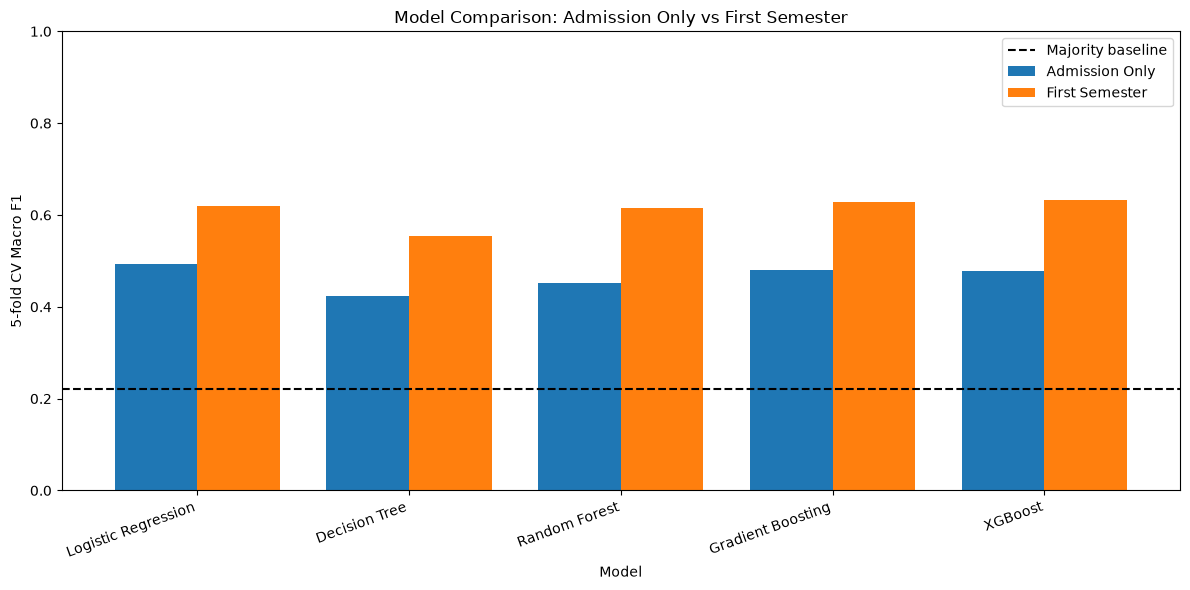

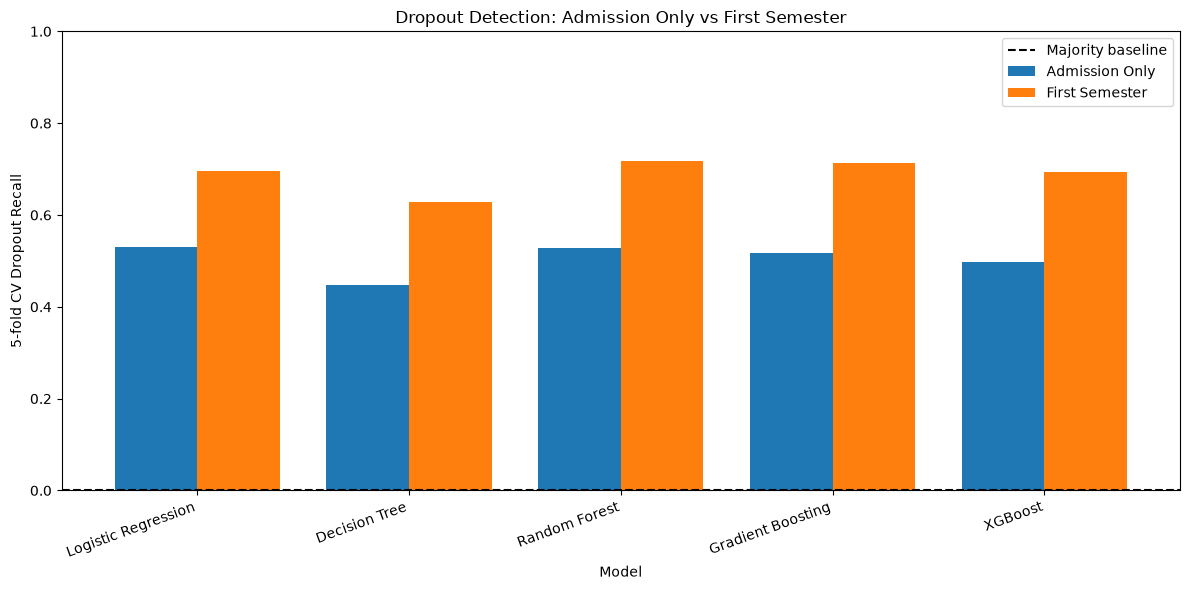

,First Semester - Admission Only,Admission + Financial - Admission Only,First Semester + Financial - First Semester
Model,,,
Random Forest,0.1637,0.0546,0.0330
XGBoost,0.1545,0.0605,0.0316
Gradient Boosting,0.1491,0.0505,0.0323
Decision Tree,0.1293,0.0514,0.0249
Logistic Regression,0.1282,0.0537,0.0463


In [17]:
results_dir = Path("part_d_results")
results_dir.mkdir(parents=True, exist_ok=True)
comparison_results.to_csv(results_dir / "model_cv_comparison.csv", index=False)
baseline_table.to_csv(results_dir / "majority_class_baseline.csv")

primary_sets = ["Admission Only", "First Semester"]
metric_plot = comparison_results[comparison_results["Feature Set"].isin(primary_sets)].pivot(
    index="Model", columns="Feature Set", values="CV f1_macro Mean"
).reindex(index=list(models), columns=primary_sets)

ax = metric_plot.plot(kind="bar", figsize=(12, 6), width=0.78)
ax.axhline(baseline_results["f1_macro"]["mean"], color="black", linestyle="--", label="Majority baseline")
ax.set_ylabel("5-fold CV Macro F1")
ax.set_xlabel("Model")
ax.set_title("Model Comparison: Admission Only vs First Semester")
ax.set_ylim(0, 1)
ax.legend()
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(results_dir / "model_comparison_macro_f1.png", dpi=200, bbox_inches="tight")
plt.show()

recall_plot = comparison_results[comparison_results["Feature Set"].isin(primary_sets)].pivot(
    index="Model", columns="Feature Set", values="CV dropout_recall Mean"
).reindex(index=list(models), columns=primary_sets)

ax = recall_plot.plot(kind="bar", figsize=(12, 6), width=0.78)
ax.axhline(baseline_results["dropout_recall"]["mean"], color="black", linestyle="--", label="Majority baseline")
ax.set_ylabel("5-fold CV Dropout Recall")
ax.set_xlabel("Model")
ax.set_title("Dropout Detection: Admission Only vs First Semester")
ax.set_ylim(0, 1)
ax.legend()
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(results_dir / "model_comparison_dropout_recall.png", dpi=200, bbox_inches="tight")
plt.show()

f1_scenarios = comparison_results.pivot(index="Model", columns="Feature Set", values="CV f1_macro Mean")
scenario_improvement = pd.DataFrame({
    "First Semester - Admission Only": f1_scenarios["First Semester"] - f1_scenarios["Admission Only"],
    "Admission + Financial - Admission Only": f1_scenarios["Admission + Financial"] - f1_scenarios["Admission Only"],
    "First Semester + Financial - First Semester": f1_scenarios["First Semester + Financial"] - f1_scenarios["First Semester"]
}).sort_values("First Semester - Admission Only", ascending=False)
scenario_improvement.to_csv(results_dir / "feature_set_improvements.csv")
display(scenario_improvement.round(4))

In [18]:
selection_feature_set = "First Semester"
shortlist_table = comparison_results[comparison_results["Feature Set"] == selection_feature_set].sort_values(
    ["CV f1_macro Mean", "CV dropout_recall Mean", "CV f1_macro Std"],
    ascending=[False, False, True]
).head(3).reset_index(drop=True)

shortlisted_models = shortlist_table["Model"].tolist()
shortlisted_pipelines = {
    name: Pipeline([
        ("preprocessing", clone(preprocessors[selection_feature_set])),
        ("model", clone(models[name]))
    ])
    for name in shortlisted_models
}

shortlist_table.to_csv(results_dir / "top_three_models.csv", index=False)
display(shortlist_table.round(4))

trained_shortlist = {
    name: clone(pipeline).fit(X_train[feature_sets[selection_feature_set]], y_train_encoded)
    for name, pipeline in shortlisted_pipelines.items()
}
print("Shortlisted models:", shortlisted_models)

,Feature Set,Model,Number of Features,CV accuracy Mean,CV accuracy Std,CV f1_macro Mean,CV f1_macro Std,CV balanced_accuracy Mean,CV balanced_accuracy Std,CV dropout_recall Mean,CV dropout_recall Std,CV dropout_precision Mean,CV dropout_precision Std,Train F1 Macro Mean,F1 Generalization Gap,CV Fit Time Mean
0,First Semester,XGBoost,24,0.7149,0.0195,0.6320,0.0149,0.6266,0.0134,0.6939,0.0238,0.7352,0.0201,0.9994,0.3673,0.4364
1,First Semester,Gradient Boosting,24,0.7251,0.0154,0.6291,0.0222,0.6250,0.0183,0.7132,0.0274,0.7422,0.0296,0.7310,0.1019,1.9129
2,First Semester,Logistic Regression,24,0.7152,0.0049,0.6206,0.0099,0.6164,0.0065,0.6966,0.0213,0.7143,0.0157,0.6793,0.0587,0.1855


Shortlisted models: ['XGBoost', 'Gradient Boosting', 'Logistic Regression']


In [19]:
oof_predictions = {}
oof_metrics = []

def oof_report(model_name, predictions):
    report = classification_report(
        y_train_encoded,
        predictions,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
    for class_name in class_names:
        oof_metrics.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1": report[class_name]["f1-score"],
            "Support": int(report[class_name]["support"])
        })

for model_name, pipeline in shortlisted_pipelines.items():
    predictions = cross_val_predict(
        pipeline,
        X_train[feature_sets[selection_feature_set]],
        y_train_encoded,
        cv=cv,
        n_jobs=2
    )
    oof_predictions[model_name] = predictions
    oof_report(model_name, predictions)

cv_class_performance = pd.DataFrame(oof_metrics)
cv_class_performance.to_csv(results_dir / "shortlist_oof_class_performance.csv", index=False)
display(cv_class_performance.round(4))

,Model,Class,Precision,Recall,F1,Support
0,XGBoost,Dropout,0.7353,0.6939,0.7140,1137
1,XGBoost,Enrolled,0.4442,0.3134,0.3675,635
2,XGBoost,Graduate,0.7641,0.8727,0.8148,1767
3,Gradient Boosting,Dropout,0.7420,0.7133,0.7274,1137
4,Gradient Boosting,Enrolled,0.4731,0.2630,0.3381,635
5,Gradient Boosting,Graduate,0.7587,0.8987,0.8228,1767
6,Logistic Regression,Dropout,0.7142,0.6966,0.7053,1137
7,Logistic Regression,Enrolled,0.4855,0.2630,0.3412,635
8,Logistic Regression,Graduate,0.7536,0.8896,0.8160,1767


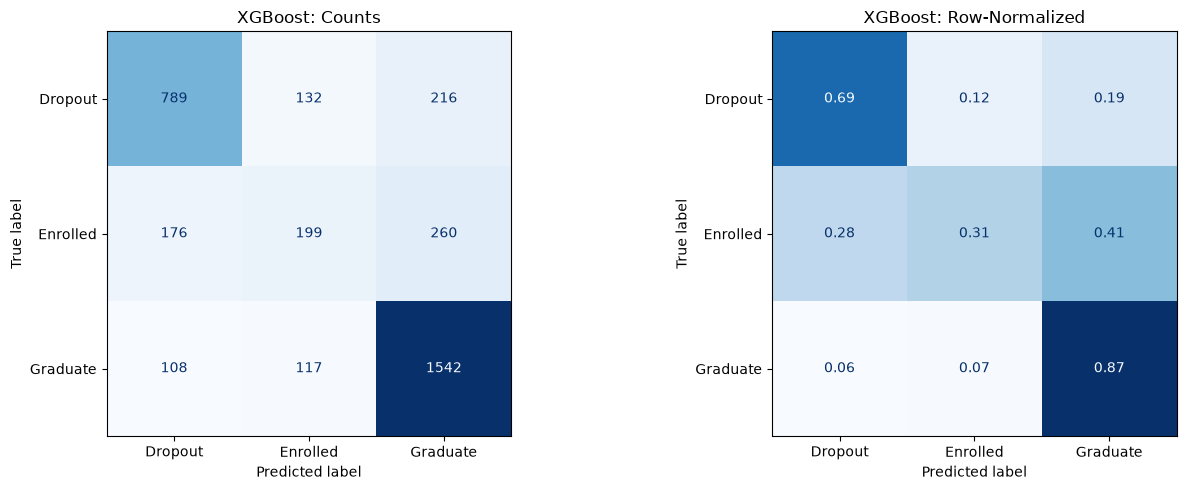

,Actual,Predicted,Count,Share of All Errors
0,Enrolled,Graduate,260,0.2577
1,Dropout,Graduate,216,0.2141
2,Enrolled,Dropout,176,0.1744
3,Dropout,Enrolled,132,0.1308
4,Graduate,Enrolled,117,0.1160
5,Graduate,Dropout,108,0.1070


In [20]:
best_model_name = shortlisted_models[0]
best_oof_predictions = oof_predictions[best_model_name]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, normalization, title, value_format in [
    (axes[0], None, "Counts", "d"),
    (axes[1], "true", "Row-Normalized", ".2f")
]:
    cm = confusion_matrix(
        y_train_encoded,
        best_oof_predictions,
        labels=np.arange(len(class_names)),
        normalize=normalization
    )
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=value_format
    )
    ax.set_title(f"{best_model_name}: {title}")

plt.tight_layout()
plt.savefig(results_dir / "best_model_cv_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

error_table = pd.DataFrame({
    "Actual": label_encoder.inverse_transform(y_train_encoded),
    "Predicted": label_encoder.inverse_transform(best_oof_predictions)
})

error_counts = (
    error_table.loc[error_table["Actual"] != error_table["Predicted"]]
    .groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
    .reset_index(drop=True)
)
error_counts["Share of All Errors"] = error_counts["Count"] / error_counts["Count"].sum()
error_counts.to_csv(results_dir / "best_model_cv_error_types.csv", index=False)
display(error_counts.round(4))